In [1]:
%matplotlib inline
from hcipy import hcipy as hci
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class FocalPlaneMask(hci.OpticalElement):
    def __init__(self, input_grid, transm_field):
        self.input_grid = input_grid
        self.transm_field = transm_field
    def forward(self, wavefront):
        print("wavefront\n{}\n".format(wavefront))
        wavefront.electric_field *= self.transm_field
        return wavefront
    def backward(self, wavefront):
        wavefront.electric_field *= self.transm_field
        return wavefront

In [3]:
class SleecCoronagraph(hci.OpticalElement):
    
    def __init__(self, input_grid, focal_plane_mask, lyot_stop=None):
        if hasattr(focal_plane_mask, 'input_grid'):
            grid = focal_plane_mask.input_grid
            self.focal_plane_mask = focal_plane_mask
        else:
            grid = focal_plane_mask.grid
            self.focal_plane_mask = hci.Apodizer(focal_plane_mask)
        if lyot_stop is not None and not hasattr(lyot_stop, 'input_grid'):
            lyot_stop = hci.Apodizer(lyot_stop)
        self.lyot_stop = lyot_stop
        self.prop = hci.FraunhoferPropagator(input_grid, focal_plane_mask.input_grid)
        
    def forward(self, wavefront):
        wf_foc = self.prop.forward(wavefront)  # Field incident on FPM
        wf_foc.electric_field = self.focal_plane_mask.forward(wf_foc).electric_field
        print("DEBUG")
        hci.imshow_field(wf_foc.intensity)
        plt.colorbar()
        plt.show()
        lyot = self.prop.backward(wf_foc)
#         lyot.electric_field[:] = wavefront.electric_field - lyot.electric_field        
        if self.lyot_stop is not None:
            lyot = self.lyot_stop.forward(lyot)            
        return lyot
    
    def backward(self, wavefront):
        if self.lyot_stop is not None:
            wf = self.lyot_stop.backward(wavefront)
        else:
            wf = wavefront            
        wf_foc = self.prop.forward(wf)
        wf_foc.electric_field = self.focal_plane_mask.backward(wf_foc).electric_field        
        pup = self.prop.backward(wf_foc)
        pup.electric_field[:] = wavefront.electric_field = wf_foc.electric_field        
        return pup

In [4]:
pupil_grid = hci.make_pupil_grid(128)
focal_grid = hci.make_focal_grid(pupil_grid, 8, 32)
prop = hci.FraunhoferPropagator(pupil_grid, focal_grid)

In [5]:
aperture = hci.circular_aperture(6.0)
fpm_opacity = 1.0 - aperture(focal_grid)
fpm = FocalPlaneMask(focal_grid, fpm_opacity)
pupil = hci.Wavefront(hci.circular_aperture(1)(pupil_grid))

In [6]:
coro = SleecCoronagraph(pupil_grid, fpm)

wavefront

DEBUG


/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


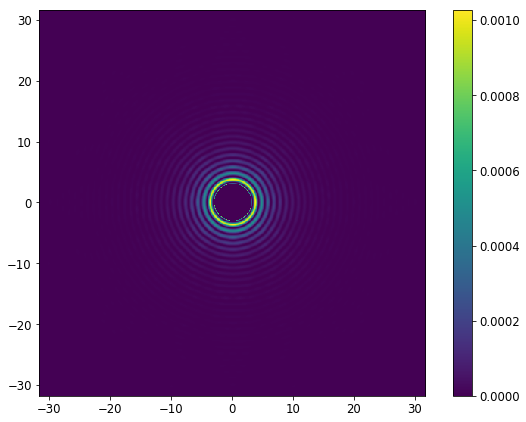

In [7]:
lyot_plane = coro(pupil)

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


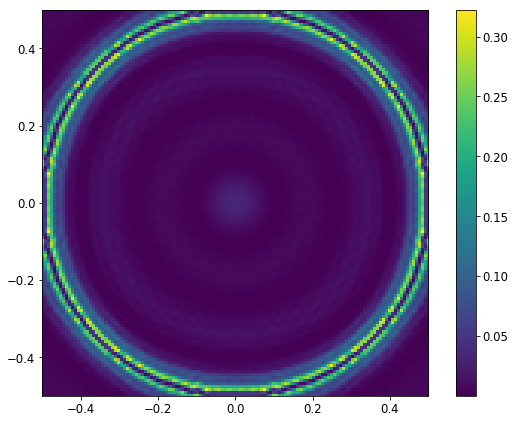

In [8]:
hci.imshow_field(lyot_plane.intensity)
plt.colorbar()

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


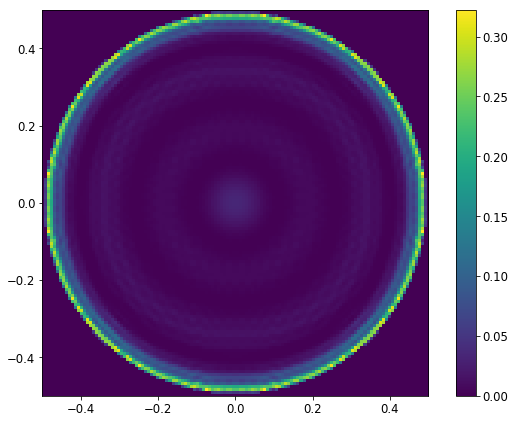

In [9]:
# lyot_stop = hci.Apodizer(hci.circular_aperture(0.8078)(pupil_grid))
lyot_stop = hci.Apodizer(hci.circular_aperture(254.0/256)(pupil_grid))
prop = hci.FraunhoferPropagator(pupil_grid, focal_grid)
img = prop(lyot_stop(lyot_plane))
img_ref = prop(pupil)
hci.imshow_field(lyot_stop(lyot_plane).intensity)
plt.colorbar()

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


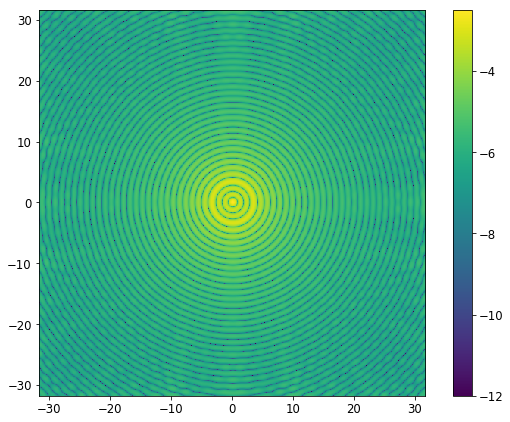

In [10]:
hci.imshow_field(np.log10(img.intensity / img_ref.intensity.max()), vmin=-12)
plt.colorbar()

In [11]:
dm = hci.make_xinetics_influence_functions(pupil_grid, 48, 1.0/47.)

FileNotFoundError: [Errno 2] No such file or directory: '/home/pinchen/sleec/hcipy/optics/influence_dm5v2.fits'